# BBKS peak statistics and density profiles from a filtered Gaussian random field

This notebook implements the BBKS peak statistics and §VII density-profile calculations from a
**single specification of the filtered Gaussian field**.

$$
P(k),\quad W(kR_f),\quad R_f
\;\Longrightarrow\;
\sigma_0,\sigma_1,\sigma_2,\gamma,R_*
\;\Longrightarrow\;
\begin{cases}
\text{peak abundance},\\
P_x(x\mid\nu),\\
P_{ep}(e,p\mid x),\\
\text{finite-}r\text{ peak profiles}.
\end{cases}
$$

The reason from this separation of the polynomial and filtering part comes from the fact that at the beginning of BBKS the power spectrum was presented as a power law to which could be applied a smoothing, so the code was built in this way

The overall normalization of $P(k)$ is irrelevant: the peak-shape quantities use ratios of spectral
moments and the profiles use the normalized correlation function $\psi=\xi/\xi(0)$.

The notebook keeps both the BBKS fitting formula and the exact Appendix-A calculation. This is
useful here because the example below has $\gamma\simeq0.882$, outside the $0.3\le\gamma\le0.7$
range quoted for the fitting formula.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import quad, dblquad, trapezoid, simpson
from scipy.special import erf, spherical_jn, hyp1f1
from scipy.optimize import minimize

%matplotlib inline

plt.rcParams.update({
    "figure.figsize": (7.5, 5),
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "lines.linewidth": 1.8,
})

TWO_PI2 = 2.0 * np.pi**2


## 1. Model definition: specify the power spectrum and filter once

Since the spectra of interest are power law (of power $n$) with gaussian smoothing (of radius $R_f$) we will
use this as input, in this notebook all fields are Gaussian and normalizations will make 
the amplitude parameter redundant so is not present.
For this specific case the spectral parameters reads:
$$
\gamma=\sqrt{\frac{n+3}{n+5}},
\qquad
R_*=R_f\sqrt{\frac{6}{n+5}},
$$
which provide analytic checks on the numerical integrated spectral integrals.

Since BBKS uses the power spectrum and not the dimensonless power spectrum we will specify the first.

In [2]:
# ---- USER INPUT: change the field here and nowhere else --------------------

n_index = 0 # so we have a k^3 dimensionless P
R_f = 1.0

Pk = lambda k: k**n_index
W  = lambda k, R: np.exp(-0.5 * (k * R)**2)

# Numerical controls; these do not define the physical model only the numerical integration.
K_MIN = 1e-6
K_MAX = 30.0 / R_f
N_GAUSS = 4000
# -----------------------------------------------------------------------------


### Spectral parameters extraction

The spectral moments are

$$
\sigma_j^2=\int_0^\infty d\ln k\,k^{2j}\mathcal{P}(k),
\qquad
\gamma=\frac{\sigma_1^2}{\sigma_0\sigma_2},
\qquad
R_*=\sqrt3\,\frac{\sigma_1}{\sigma_2}.
$$

These are the two spectral-shape parameters used by the local BBKS peak statistics.

For finite-radius profiles we need the full normalized two-point correlation,

$$
\xi(r)=\int_0^\infty d\ln k \,\mathcal{P}(k)\,j_0(kr),
\qquad
\psi(r)=\frac{\xi(r)}{\xi(0)}.
$$

All of these are derived from the **same** `field` defined above; there is no second spectrum/filter
definition later in the notebook.

In [3]:
TWO_PI2 = 2.0 * np.pi**2


class SmoothedGaussianField:
    '''Spectral moments and profile functions of a filtered Gaussian random field.'''

    def __init__(self, Pk, W, R_f, kmin=1e-6, kmax=None, nk=4000):
        self.Pk, self.W, self.R_f = Pk, W, R_f
        self.kmin = kmin
        self.kmax = kmax if kmax is not None else 30.0 / R_f   # Gaussian filter -> safe cutoff
        self.sigma0 = np.sqrt(self.moment2(0))
        self.sigma1 = np.sqrt(self.moment2(1))
        self.sigma2 = np.sqrt(self.moment2(2))
        self.gamma = self.sigma1**2 / (self.sigma0 * self.sigma2)
        self.Rstar = np.sqrt(3.0) * self.sigma1 / self.sigma2
        # fixed Gauss-Legendre nodes, for fast vectorised evaluation of psi & co.
        xg, wg = np.polynomial.legendre.leggauss(nk)
        self._k = 0.5 * (self.kmax - self.kmin) * xg + 0.5 * (self.kmax + self.kmin)
        self._w = 0.5 * (self.kmax - self.kmin) * wg
        self._base = (self._w * self.Pk(self._k) * self.W(self._k, self.R_f)**2
                      / (TWO_PI2 * self.sigma0**2))

    def moment2(self, j):
        '''Return sigma_j^2.'''
        f = lambda k: k**(2 + 2 * j) * self.Pk(k) * self.W(k, self.R_f)**2 / TWO_PI2
        val, _ = quad(f, self.kmin, self.kmax, limit=400)
        return val

    def profile_functions(self, u):
        '''Return psi, dpsi/du, Laplacian_u psi, and S at u=r/Rstar.'''
        u = np.atleast_1d(np.asarray(u, float))
        Y = np.outer(u, self._k * self.Rstar)                 # (n_u, n_k)
        j0, j1, j2 = (spherical_jn(m, Y) for m in (0, 1, 2))
        b, k, Rs = self._base, self._k, self.Rstar
        psi = j0 @ (b * k**2)
        dpsi = -Rs * (j1 @ (b * k**3))
        lap = -Rs**2 * (j0 @ (b * k**4))
        S = -(Rs**2 / 3.0) * (j2 @ (b * k**4))
        return psi, dpsi, lap, S

    def psi(self, u):
        return self.profile_functions(u)[0]


field = SmoothedGaussianField(Pk, W, R_f, K_MIN, K_MAX, N_GAUSS)
gamma = field.gamma
R_star = field.Rstar

print(f"  sigma_0 = {field.sigma0:.6e}")
print(f"  sigma_1 = {field.sigma1:.6e}")
print(f"  sigma_2 = {field.sigma2:.6e}")
print(f"  gamma   = {field.gamma:.6f}        [= sigma_1^2/(sigma_0 sigma_2)]")
print(f"  R_*     = {field.Rstar:.6f}        [= sqrt(3) sigma_1/sigma_2]  (same units as R_f)")
print(f"  R_*/R_f = {field.Rstar/R_f:.6f}")

# --- analytic cross-check, valid for a pure power law + Gaussian filter -------
g_exact = np.sqrt((n_index + 3) / (n_index + 5))           # BBKS eq. (E3)
Rs_exact = R_f * np.sqrt(6.0 / (n_index + 5))              # = sqrt(3) sigma_1/sigma_2
print(f"\nanalytic check (power law + Gaussian):  gamma = {g_exact:.6f},  R_* = {Rs_exact:.6f}")

  sigma_0 = 1.498279e-01
  sigma_1 = 1.835009e-01
  sigma_2 = 2.901404e-01
  gamma   = 0.774597        [= sigma_1^2/(sigma_0 sigma_2)]
  R_*     = 1.095445        [= sqrt(3) sigma_1/sigma_2]  (same units as R_f)
  R_*/R_f = 1.095445

analytic check (power law + Gaussian):  gamma = 0.774597,  R_* = 1.095445


## 2. Peak abundance: BBKS §IV

The differential number density of peaks of height $\nu=F/\sigma_0$ is

$$
N_{\rm pk}(\nu)\,d\nu =
\frac{1}{(2\pi)^2}\frac{1}{R_*^3}
e^{-\nu^2/2}G(\gamma,\gamma\nu)\,d\nu
\qquad\text{(eq. 4.3)}.
$$

The cumulative density above threshold is

$$
n_{\rm pk}(>\nu)=\int_\nu^\infty N_{\rm pk}(\nu')\,d\nu'.
$$

The next cells define the BBKS fitting function \(G\) and then evaluate these quantities for the
$\gamma$ and $R_*$ derived from the field in §1.


### Differential and cumulative number densities, eq. (4.3)

In [4]:
def differential_number_density(nu, gamma, R_star):
    """
    N_pk(nu): comoving differential number density of peaks per unit nu,
    eq. (4.3). nu may be a scalar or a numpy array.
    """
    nu = np.asarray(nu, dtype=float)
    w = gamma * nu
    prefactor = 1.0 / (2.0 * np.pi) ** 2 / R_star**3
    return prefactor * np.exp(-nu**2 / 2.0) * G(gamma, w)


def cumulative_number_density(nu, gamma, R_star, nu_upper=40.0):
    """
    n_pk(>nu): comoving number density of peaks with height above nu,
    obtained by integrating the differential density (eq. 4.3) from nu
    to nu_upper (effectively infinity - the integrand is already
    negligible well before nu ~ 40 for any reasonable gamma).

    nu may be a scalar or a numpy array; returns the same shape.
    """
    nu = np.asarray(nu, dtype=float)
    scalar_input = nu.ndim == 0

    def integrand(x):
        return differential_number_density(x, gamma, R_star)

    flat = np.atleast_1d(nu)
    result = np.empty_like(flat)
    for i, nu_i in enumerate(flat):
        upper = max(nu_upper, nu_i + 10.0)  # keep upper limit safely above nu_i
        val, _ = quad(integrand, nu_i, upper, limit=200)
        result[i] = val

    return result.item() if scalar_input else result

### Exact integrated $G(\gamma, w)$ from Appendix A (eq. A19)

The fitting formula present in BBKS is only calibrated to be accurate for $0.3 \le \gamma \le 0.7$. Since PBH spectra of interest are more peaked have $\gamma$ closer to one, so we skip the fitting formula and perform the calculation with the integrated exact one, accepting the greatly increased computational cost

$$G(\gamma, x_*) = \int_0^\infty dx\, f(x)\, \frac{\exp\!\big[-(x-x_*)^2/2(1-\gamma^2)\big]}{\sqrt{2\pi(1-\gamma^2)}}$$

where $x = (\lambda_1+\lambda_2+\lambda_3)/\sigma_2$ is the (normalized) trace of the curvature tensor, restricted to $x\ge 0$ since all eigenvalues are non-negative at a maximum, and $f(x)$ is given in closed form by eq. (A15):

$$f(x) = \frac{x^3-3x}{2}\left[\mathrm{erf}\!\left(\sqrt{\tfrac{5}{2}}\,x\right) + \mathrm{erf}\!\left(\sqrt{\tfrac{5}{2}}\,\frac{x}{2}\right)\right] + \sqrt{\frac{2}{5\pi}}\left[\left(\frac{31x^2}{4}+\frac{8}{5}\right)e^{-5x^2/8} + \left(\frac{x^2}{2}-\frac{8}{5}\right)e^{-5x^2/2}\right]$$

$f(x)$ satisfies $f(x)\to x^3-3x$ as $x\to\infty$ (the spherical-peak limit) and $f(x)\sim x^8$ as $x\to 0$ (the "remarkable cancellation to eighth order" BBKS mention below eq. A16). We use this exact $f$ and $G$ below, alongside the fitted versions already defined above, so the two can be compared directly.

The same exact \(f(x)\) will also be reused for the peak-curvature distribution in §3.


In [5]:
from scipy.special import erf

def f_exact(x):
    """Exact f(x), eq. (A15). Defined for x >= 0 (sum of maximum's curvature eigenvalues / sigma2)."""
    x = np.asarray(x, dtype=float)
    term1 = 0.5 * (x**3 - 3*x) * (erf(np.sqrt(5/2)*x) + erf(np.sqrt(5/2)*x/2))
    term2 = np.sqrt(2/(5*np.pi)) * ((31*x**2/4 + 8/5)*np.exp(-5*x**2/8) + (x**2/2 - 8/5)*np.exp(-5*x**2/2))
    return term1 + term2

def f_bbks(x):
    '''BBKS eq. (A15). The small-x series (A16) is used below x = 0.2, where the
    closed form suffers from catastrophic cancellation.'''
    x = np.asarray(x, float)
    out = np.empty_like(x)
    sm = x < 0.2
    xs, xb = x[sm], x[~sm]
    out[sm] = (3**5 * 5**1.5 / (7 * 2**11 * np.sqrt(2 * np.pi))) * xs**8 * (1 - 5 * xs**2 / 8)
    out[~sm] = ((xb**3 - 3 * xb) * (erf(np.sqrt(2.5) * xb) + erf(np.sqrt(2.5) * xb / 2)) / 2
                + np.sqrt(2 / (5 * np.pi)) * ((31 * xb**2 / 4 + 8 / 5) * np.exp(-5 * xb**2 / 8)
                                              + (xb**2 / 2 - 8 / 5) * np.exp(-5 * xb**2 / 2)))
    return out


def G_exact(gamma, w, x_upper=60.0):
    """
    Exact G(gamma, w), eq. (A19), by numerically integrating f_exact(x) against
    the Gaussian kernel over x in [0, x_upper]. x_upper is pushed out further
    than w automatically so the (Gaussian-suppressed) tail is always captured.
    """
    sigma = np.sqrt(1.0 - gamma**2)

    def integrand(x):
        return f_exact(x) * np.exp(-(x - w)**2 / (2*sigma**2)) / (np.sqrt(2*np.pi)*sigma)

    upper = max(x_upper, w + 10*sigma + 10.0)
    val, _ = quad(integrand, 0.0, upper, limit=300)
    return val


def exact_differential_number_density(nu, gamma, R_star):
    """N_pk(nu) using the exact G (eq. A19) instead of the fitting formula (eq. 4.4)."""
    nu = np.asarray(nu, dtype=float)
    prefactor = 1.0 / (2.0 * np.pi) ** 2 / R_star**3

    flat = np.atleast_1d(nu)
    result = np.empty_like(flat, dtype=float)
    for i, nu_i in enumerate(flat):
        w = gamma * nu_i
        result[i] = prefactor * np.exp(-nu_i**2 / 2.0) * G_exact(gamma, w)
    return result.item() if nu.ndim == 0 else result


def exact_cumulative_number_density(nu, gamma, R_star, nu_upper=40.0):
    """n_pk(>nu) obtained by integrating the exact differential density."""
    nu = np.asarray(nu, dtype=float)
    scalar_input = nu.ndim == 0

    def integrand(x):
        return exact_differential_number_density(x, gamma, R_star)

    flat = np.atleast_1d(nu)
    result = np.empty_like(flat, dtype=float)
    for i, nu_i in enumerate(flat):
        upper = max(nu_upper, nu_i + 10.0)
        val, _ = quad(integrand, nu_i, upper, limit=100)
        result[i] = val

    return result.item() if scalar_input else result

### Sanity checks

$f(x)$ should approach $x^3-3x$ for large $x$, and vanish at $x=0$:

In [6]:
for x in [5, 10, 20]:
    print(f"x={x:5.1f}   f(x)={f_exact(x): .4f}   x^3-3x={x**3-3*x: .4f}")
print(f"\nf(0) = {f_exact(0.0): .6f}  (should be 0)")

x=  5.0   f(x)= 110.0000   x^3-3x= 110.0000
x= 10.0   f(x)= 970.0000   x^3-3x= 970.0000
x= 20.0   f(x)= 7940.0000   x^3-3x= 7940.0000

f(0) =  0.000000  (should be 0)


### Aboundance plots

In [7]:
R_star_fixed = R_star
gammas = [0.3, 0.5, 0.7, 0.9]
nu_min, nu_max = -3, 6
nu = np.linspace(nu_min, nu_max, 150)
yd = []
yc = []
for g in gammas:
    yd.append(exact_differential_number_density(nu, g, R_star_fixed))
    yc.append(exact_cumulative_number_density(nu, g, R_star_fixed))

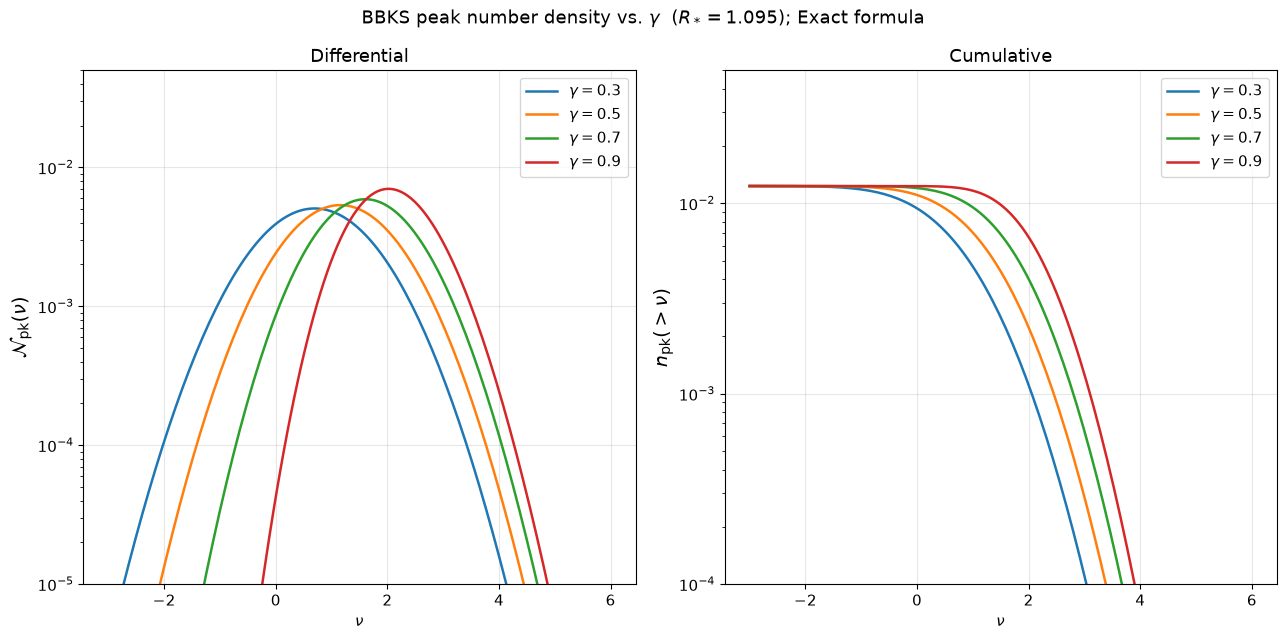

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))

for g in gammas:
    axes[0].plot(nu, yd[gammas.index(g)], label=fr"$\gamma={g}$")
    axes[1].plot(nu, yc[gammas.index(g)], label=fr"$\gamma={g}$")

axes[0].set_xlabel(r"$\nu$"); axes[0].set_ylabel(r"$\mathcal{N}_{\rm pk}(\nu)$", fontsize=14)
axes[0].set_title("Differential"); axes[0].set_yscale("log"); axes[0].grid(alpha=0.3); axes[0].legend()
axes[0].set_ylim(1e-5, 5e-2)

axes[1].set_xlabel(r"$\nu$"); axes[1].set_ylabel(r"$n_{\rm pk}(>\nu)$", fontsize=14)
axes[1].set_title("Cumulative"); axes[1].set_yscale("log"); axes[1].grid(alpha=0.3); axes[1].legend()
axes[1].set_ylim(1e-4, 5e-2)

fig.suptitle(rf"BBKS peak number density vs. $\gamma$  ($R_* = {R_star_fixed:.3f}$); Exact formula")
fig.tight_layout()
plt.show()

---

## 3. Peak curvature and shape — BBKS §VII

Everything above describes *how many* peaks there are. Section VII of BBKS describes *what they look like*. Near a maximum the profile is the Taylor expansion of eq. (7.1),

$$F(\mathbf r) = F(0) - \sum_i \lambda_i r_i^2/2 ,$$

so the shape at lowest order is fixed by the three curvature eigenvalues $\lambda_1 \ge \lambda_2 \ge \lambda_3 > 0$. BBKS repackage them into one scale and two shape parameters (eqs. [A2], [7.3]):

$$x = \frac{\lambda_1+\lambda_2+\lambda_3}{\sigma_2} = \frac{-\nabla^2 F}{\sigma_2}, \qquad
e = \frac{\lambda_1-\lambda_3}{2\sum_i\lambda_i}, \qquad
p = \frac{\lambda_1-2\lambda_2+\lambda_3}{2\sum_i\lambda_i} .$$

$x$ measures how sharply curved (how compact) the peak is, $e \ge 0$ is the **ellipticity** in the 1–3 plane, and $p$ is the **prolateness**: $p = e$ for an oblate spheroid, $p = -e$ for a prolate one, $p = 0$ for the generic triaxial case.

The two sections below implement the corresponding distributions:

| equation | quantity | figure |
|---|---|---|
| (7.5) | $P_x(x\mid\nu)$ — curvature at fixed peak height | Fig. 6 |
| (7.6) | $P_{ep}(e,p\mid x)$ — ellipticity and prolateness at fixed curvature | Fig. 7 |

### Curvature at fixed height, eq. (7.5)

$$P_x(x\mid\nu)\,dx = \frac{\mathcal N_{\rm pk}(\nu, x)\,dx}{\mathcal N_{\rm pk}(\nu)}
= \frac{\exp\big[-(x-x_*)^2/2(1-\gamma^2)\big]}{[2\pi(1-\gamma^2)]^{1/2}}\,\frac{f(x)}{G(\gamma,\gamma\nu)},
\qquad x_* = \gamma\nu$$

This needs nothing new: it is exactly the integrand of $G$ from eq. (A19), divided by $G$ itself. So `f_exact` and `G_exact`, already defined above, are all we need — and the fact that $\int_0^\infty P_x\,dx = 1$ follows by construction, which makes it a free check on the earlier code.

The Gaussian factor pulls $x$ towards $x_* = \gamma\nu$, while $f(x) \sim x^8$ at small $x$ pushes it away from zero. Their product is sharply peaked, so **higher peaks are more curved**, i.e. more compact relative to $R_*$.

In [9]:
# ---- eq. (7.5): distribution of the peak curvature x = -grad^2 F / sigma_2 ----

def P_x_given_nu(x, nu, gamma):
    """
    P_x(x | nu), eq. (7.5): the probability distribution of the peak curvature
    x = -\\nabla^2 F/\\sigma_2 for peaks of height nu,

        P_x(x|nu) = f(x) * exp[-(x-x_*)^2 / 2(1-gamma^2)]
                         / sqrt(2 pi (1-gamma^2)) / G(gamma, gamma*nu),

    with x_* = gamma*nu, f(x) from eq. (A15) and G from eq. (A19).

    This is just N_pk(nu, x) / N_pk(nu), i.e. eq. (A14) divided by eq. (A18):
    the integrand of G, normalised by G itself.  Defined for x >= 0.

    x may be an array; nu and gamma must be scalars (G is evaluated once).
    """
    x = np.asarray(x, dtype=float)
    sigma = np.sqrt(1.0 - gamma**2)
    x_star = gamma * nu

    gaussian = np.exp(-(x - x_star)**2 / (2*sigma**2)) / (np.sqrt(2*np.pi)*sigma)
    return np.where(x >= 0.0, f_bbks(x) * gaussian, 0.0) / G_exact(gamma, x_star)

def P_x_given_nu_fast(x, nu, gamma):
    '''BBKS eq. (7.5), up to the normalisation G(gamma, x_*).'''
    xstar = gamma * nu
    return (f_bbks(x) * np.exp(-(x - xstar)**2 / (2 * (1 - gamma**2)))
            / np.sqrt(2 * np.pi * (1 - gamma**2)))

def x_mode(nu, gamma, x_grid=None):
    """Most probable curvature x_m of P_x(x|nu), found on a fine grid."""
    if x_grid is None:
        x_grid = np.linspace(0.0, 20.0, 20001)
    P = P_x_given_nu(x_grid, nu, gamma)
    return x_grid[np.argmax(P)]

### Plot $P_x(x\mid\nu)$ .

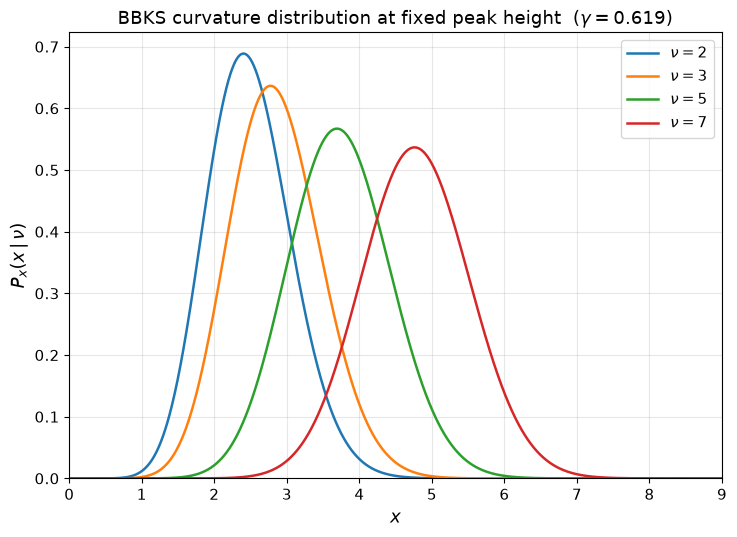

  nu             x*         peak x      area
   2           1.24           2.40   1.00000
   3           1.86           2.77   1.00000
   5           3.09           3.69   1.00000
   7           4.33           4.76   1.00000


In [10]:
# --- Figure 6: P_x(x|nu) for gamma = 0.619 and nu = 1, 2, 3, 4 ---

gamma_fig6 = 0.619
nus_fig6 = [2, 3, 5, 7]

x_plot = np.linspace(0.0, 12.0, 4001)

fig, ax = plt.subplots(figsize=(7.5, 5.5))

for nu in nus_fig6:
    P = P_x_given_nu(x_plot, nu, gamma_fig6)
    ax.plot(x_plot, P, label=fr"$\nu = {nu}$")
    i = np.argmax(P)

ax.set_xlabel(r"$x$", fontsize=13)
ax.set_ylabel(r"$P_x(x\,|\,\nu)$", fontsize=13)
ax.set_title(rf"BBKS curvature distribution at fixed peak height  ($\gamma = {gamma_fig6}$)")
ax.set_xlim(0, 9)
ax.set_ylim(0, None)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

print(f"{'nu':>4} {'x*':>14} {'peak x':>14} {'area':>9}")
#position of peak and check area under the curve for each nu
for nu in nus_fig6:
    P = P_x_given_nu(x_plot, nu, gamma_fig6)
    xm = x_plot[np.argmax(P)] 
    print(f"{nu:>4} {nu*gamma_fig6:>14.2f} {xm:>14.2f} {trapezoid(P, x_plot):>9.5f}")

### Curvature summary across peak height

The normalized $P_x(x\mid\nu)$ curves above show that the mode moves only gradually with $\nu$
and the distributions overlap substantially. The curvature is therefore only loosely tied to peak
height, which is why $x$ must be carried as a separate variable rather than replaced by
$x_*=\gamma\nu$.


In [11]:
def x_stats(gamma, nu):
    """Return x_* = gamma*nu, mean, mode, and standard deviation of P_x(x|nu)."""
    if not np.isfinite(gamma) or not (0.0 < gamma < 1.0):
        raise ValueError(f"x_stats requires 0 < gamma < 1; got gamma = {gamma}")

    weight = lambda t: float(P_x_given_nu_fast(t, nu, gamma))
    norm = quad(weight, 0.0, np.inf, limit=400)[0]
    mean = quad(lambda t: t*weight(t), 0.0, np.inf, limit=400)[0] / norm
    variance = quad(
        lambda t: (t - mean)**2 * weight(t),
        0.0, np.inf, limit=400
    )[0] / norm

    grid = np.linspace(1e-3, 15.0, 30001)
    mode = float(grid[np.argmax(P_x_given_nu_fast(grid, nu, gamma))])

    return gamma*nu, mean, mode, np.sqrt(variance)


# Literature check quoted in BBKS §VIIa.
xs_c, xm_c, xmo_c, _ = x_stats(0.62, 2.7)
print("check against BBKS Sec. VIIa (gamma=0.62, nu=2.7):")
print(
    f"  x_*={xs_c:.3f}, <x|nu>={xm_c:.3f}, most probable x={xmo_c:.3f}"
    f" = {xmo_c/xs_c:.2f} x_*   [BBKS: ~1.5 x_* ~2.5]"
)

print(f"\nthis field (gamma={field.gamma:.4f}):")
for nu_i in [1.0, 2.0, 2.68, 3.0]:
    xs_i, xm_i, xmo_i, _ = x_stats(field.gamma, nu_i)
    print(
        f"  nu={nu_i:4.2f}: x_*={xs_i:.3f}, "
        f"<x|nu>={xm_i:.3f}, x_mode={xmo_i:.3f}"
    )


check against BBKS Sec. VIIa (gamma=0.62, nu=2.7):
  x_*=1.674, <x|nu>=2.733, most probable x=2.657 = 1.59 x_*   [BBKS: ~1.5 x_* ~2.5]

this field (gamma=0.7746):
  nu=1.00: x_*=0.775, <x|nu>=1.953, x_mode=1.892
  nu=2.00: x_*=1.549, <x|nu>=2.390, x_mode=2.338
  nu=2.68: x_*=2.076, <x|nu>=2.741, x_mode=2.698
  nu=3.00: x_*=2.324, <x|nu>=2.921, x_mode=2.883


### Curvature distribution varying $\nu$

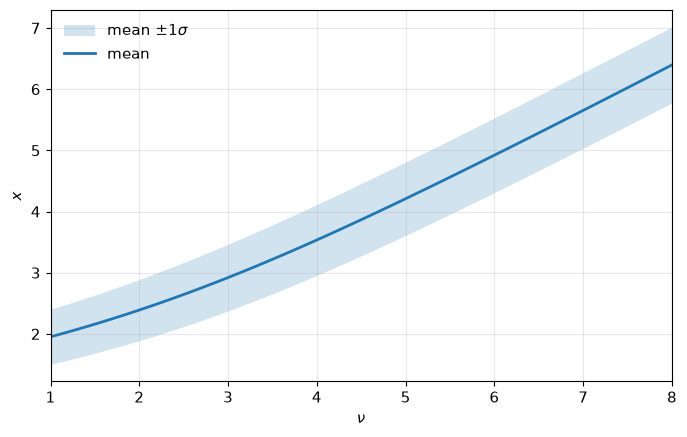

In [12]:
nu_plot = np.linspace(1.0, 8.0, 100)
stats = np.array([x_stats(field.gamma, nu) for nu in nu_plot])
x_mean = stats[:, 1]
x_mode = stats[:, 2]
x_std = stats[:, 3]

fig, ax = plt.subplots(figsize=(7, 4.5))

ax.fill_between(nu_plot, x_mean - x_std, x_mean + x_std,
                color="C0", alpha=0.2, linewidth=0, label=r"mean $\pm 1\sigma$")
ax.plot(nu_plot, x_mean, color="C0", lw=2, label="mean")

ax.set_xlabel(r"$\nu$")
ax.set_ylabel(r"$x$")
ax.set_xlim(nu_plot[0], nu_plot[-1])
ax.grid(alpha=0.3)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

In [13]:
# Auxiliary plot for the interactive profiles plot
def x_nu_plot_point(x, nu, x_mean, x_std, ax=None):
    """Plot a point (x, nu) on the x-nu plot with mean and std bands."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.fill_between(nu_plot, x_mean - x_std, x_mean + x_std,
                    color="C0", alpha=0.2, linewidth=0, label=r"mean $\pm 1\sigma$")
    ax.plot(nu_plot, x_mean, color="C0", lw=2, label="mean")
    ax.plot(nu_plot, x_mode, color="C3", lw=2, ls=":", label="mode")
    ax.plot(nu, x, "o", ms=8, mfc="none", mec="C1", mew=2,
            label=rf"point: $\nu={nu:g},\ x={x:.3f}$")
    ax.set_xlim(nu_plot[0], nu_plot[-1])
    ax.grid(alpha=0.3)
    return ax


The mode moves only gradually with $\nu$, and the distributions overlap substantially. The curvature of a peak is only loosely tied to its height — which is precisely why $x$ has to be carried around as a separate variable rather than being replaced by $x_*=\gamma\nu$.

## b) Ellipticity and prolateness at fixed curvature, eq. (7.6)

$$P_{ep}(e,p\mid\nu,x)\,de\,dp = P_{ep}(e,p\mid x)\,de\,dp
= \frac{3^2 5^{5/2}}{(2\pi)^{1/2}}\,\frac{x^8}{f(x)}\,
e^{-(5/2)x^2(3e^2+p^2)}\,W(e,p)\,de\,dp$$

Two things are worth flagging before coding this up.

**It does not depend on $\nu$.** The height enters only through the distribution of $x$, eq. (7.5). So peak shapes are controlled by curvature alone, and "high peaks are rounder" is an indirect statement: high peaks have large $x$, and large $x$ means small $e$.

**$W(e,p)$ needs a correction.** Eq. (C4) defines $W \equiv x^{-8}F(x, y{=}ex, z{=}px)\chi(e,p)$ with $F$ from eq. (A13), and prints the result as

$$W(e,p) = e(e^2-p^2)(1-2p)\big[(1+p)^2 - 9p^2\big]\chi(e,p).$$

Substituting $y = ex$, $z = px$ into eq. (A13) gives the last bracket as $(1+p)^2 - 9e^2$, not $-9p^2$. Three independent arguments say the $9e^2$ version is the intended one: only it makes $W$ "a polynomial of order 5 in both $e$ and $p$" as the text states; only it vanishes on the domain boundary $p = -(1-3e)$, since $(1+p)^2-9e^2 = (1+p-3e)(1+p+3e)$; and only it reproduces the $x \to 0$ limit of $f(x)$ in eq. (A16). The last of these is checked numerically two cells below.

The factor $\chi(e,p)$ of eq. (C3) restricts $(e,p)$ to the triangle with vertices $(0,0)$, $(\tfrac14,-\tfrac14)$, $(\tfrac12,\tfrac12)$ — the region where $\lambda_1 \ge \lambda_2 \ge \lambda_3 \ge 0$ is satisfiable.

In [14]:
# Joint distribution of ellipticity e and prolateness p ----

def chi_domain(e, p):
    """
    Characteristic function chi(e, p) of eq. (C3): 1 inside the allowed
    (e, p) triangle with vertices (0,0), (1/4,-1/4), (1/2,1/2), else 0.
    """
    e = np.asarray(e, dtype=float)
    p = np.asarray(p, dtype=float)
    lower = (e <= 0.25) & (e >= 0.0) & (p >= -e) & (p <= e)
    upper = (e > 0.25) & (e <= 0.5) & (p >= -(1.0 - 3.0*e)) & (p <= e)
    return (lower | upper).astype(float)


def W_poly(e, p):
    """
    W(e, p) of eq. (C4): x^(-8) * x^2 * F(x, y=ex, z=px) * chi(e, p), a degree-5
    polynomial in both e and p,

        W(e, p) = e (e^2 - p^2) (1 - 2p) [(1 + p)^2 - 9 e^2] chi(e, p).

    (The published eq. [C4] prints the last bracket as [(1+p)^2 - 9p^2]; that
    must be a typo, since only 9e^2 makes W of order 5 in e as stated in the
    text, and only 9e^2 reproduces the x -> 0 limit of f(x) in eq. [A16] --
    see the checks below.)
    """
    e = np.asarray(e, dtype=float)
    p = np.asarray(p, dtype=float)
    return e * (e**2 - p**2) * (1.0 - 2.0*p) * ((1.0 + p)**2 - 9.0*e**2) * chi_domain(e, p)


_EP_PREFACTOR = 3.0**2 * 5.0**2.5 / np.sqrt(2.0*np.pi)   # 3^2 5^(5/2) / (2 pi)^(1/2)


def P_ep_given_x(e, p, x):
    """
    P_ep(e, p | x), eq. (7.6):

        P(e,p|x) = [3^2 5^(5/2) / (2pi)^(1/2)] (x^8 / f(x))
                   exp[-(5/2) x^2 (3e^2 + p^2)] W(e, p).

    Independent of the peak height nu: the height only enters through the
    distribution of x, eq. (7.5).  e and p may be arrays (broadcast together).
    """
    return (_EP_PREFACTOR * x**8 / f_exact(x)
            * np.exp(-2.5 * x**2 * (3.0*e**2 + p**2)) * W_poly(e, p))


def ep_most_probable(x):
    """
    Most probable (e_m, p_m) and dispersions (sigma_e, sigma_p) of eq. (7.7),
    the large-x Gaussian approximation to eq. (7.6):

        e_m = 1 / (sqrt(5) x [1 + 6/(5x^2)]^(1/2)),   p_m = 6 e_m^4,
        sigma_e = e_m / sqrt(6),                      sigma_p = e_m / sqrt(3).

    NOTE: the published p_m reads 6 / (5 x^4 [1 + 6/(5x^2)]^2) = 30 e_m^4,
    which is 5x too large; stationarity of ln V (Appendix C) gives
    p_m = 6 e_m^4 = 6 / (25 x^4 [1 + 6/(5x^2)]^2).  The corrected value is
    the one that reproduces both the numerical mode of eq. (7.6) and BBKS's
    own quoted p_m ~ 5e-3 at x ~ 2.5.
    """
    e_m = 1.0 / (np.sqrt(5.0) * x * np.sqrt(1.0 + 6.0/(5.0*x**2)))
    p_m = 6.0 * e_m**4
    return e_m, p_m, e_m/np.sqrt(6.0), e_m/np.sqrt(3.0)


def ep_mode_numerical(x, n=1200):
    """Mode of eq. (7.6) located directly on a fine (e, p) grid."""
    e = np.linspace(1e-4, 0.5, n)
    p = np.linspace(-0.25, 0.5, n)
    E, P = np.meshgrid(e, p, indexing="ij")
    Z = P_ep_given_x(E, P, x)
    i, j = np.unravel_index(np.argmax(Z), Z.shape)
    return e[i], p[j]

### Two checks

If $W$ and the prefactor are right, eq. (7.6) must integrate to exactly 1 over the triangle for every $x$. And since the exponential $\to 1$ as $x \to 0$, eq. (7.6) also implies

$$f(x) \longrightarrow \frac{3^2 5^{5/2}}{(2\pi)^{1/2}}\left[\int\!\!\int W\,de\,dp\right] x^8 ,$$

which has to agree with the independently derived small-$x$ limit of eq. (A16), $f \to 3^5 5^{3/2} x^8 / (7\cdot 2^{11}\sqrt{2\pi})$. That fixes $\int\!\!\int W\,de\,dp = 27/71680$ — a stringent test, and one the $9p^2$ version fails by a factor of exactly 3.

In [15]:
# --- checks on eq. (7.6): unit normalisation, and consistency with f(x) ---

def integrate_ep(func):
    """Integrate func(e, p) over the allowed triangle of eq. (C3)."""
    lo, _ = dblquad(lambda p, e: func(e, p), 0.0, 0.25,
                    lambda e: -e, lambda e: e, epsabs=1e-13)
    hi, _ = dblquad(lambda p, e: func(e, p), 0.25, 0.5,
                    lambda e: -(1.0 - 3.0*e), lambda e: e, epsabs=1e-13)
    return lo + hi

print("Normalisation of P(e, p | x)  (eq. 7.6 should integrate to 1):")
for x in [0.5, 1.0, 2.0, 2.5, 4.0, 6.0]:
    print(f"   x = {x:4.1f}   integral = {integrate_ep(lambda e, p: P_ep_given_x(e, p, x)):.8f}")

# As x -> 0 the exponential -> 1, so eq. (7.6) forces
#     f(x) -> [3^2 5^(5/2)/(2pi)^(1/2)] x^8 * int W de dp,
# which must agree with the x^8 limit of eq. (A16),
#     f(x) -> 3^5 5^(3/2) / (7 * 2^11 * sqrt(2pi)) x^8.
intW = integrate_ep(W_poly)
implied = 3.0**5 * 5.0**1.5 / (7.0 * 2.0**11 * np.sqrt(2*np.pi)) / _EP_PREFACTOR
print(f"\n  int W de dp                 = {intW:.12e}")
print(f"  required by eq. (A16)       = {implied:.12e}   (= 27/71680)")
print(f"  ratio                       = {intW/implied:.12f}")

Normalisation of P(e, p | x)  (eq. 7.6 should integrate to 1):
   x =  0.5   integral = 1.00000000
   x =  1.0   integral = 1.00000000
   x =  2.0   integral = 1.00000000
   x =  2.5   integral = 1.00000000
   x =  4.0   integral = 1.00000000
   x =  6.0   integral = 1.00000000

  int W de dp                 = 3.766741071429e-04
  required by eq. (A16)       = 3.766741071429e-04   (= 27/71680)
  ratio                       = 1.000000000000


### Distribution plots as a heatmaps

BBKS draw 95%, 90% and 50% contours for $x = 1,\dots,6$ all on one set of axes. Here we instead fix a single $x$ and show the full density as a heatmap, which makes the shape of the distribution near the boundary easier to read.

Overlaid are the numerically located mode of eq. (7.6), and the most probable values plus $1\sigma$/$2\sigma$ ellipses from the large-$x$ Gaussian approximation of eq. (7.7). Set `X_FIXED` to the curvature you want; for the CDM example of § VIIa(i) ($\nu = 2.7$, $\gamma = 0.62$) the relevant value is $x \approx 2.5$.

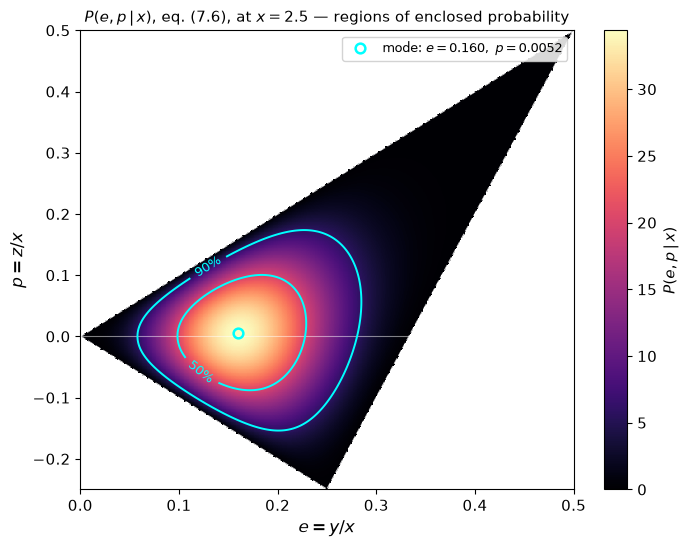

In [16]:
# --- Figure 7, as a heatmap at one fixed curvature x ---

X_FIXED = 2.5          # curvature x of the peak (in the units of the text)
KIND = "mass"          # "peak": BBKS convention, contours at that fraction of P_max
                       # "mass": highest-density regions enclosing a chosen probability
ZOOM = False            # crop to the widest contour drawn
NGRID = 600

_DEFAULT_FRACTIONS = {"mass": (0.5, 0.9), "peak": (0.95, 0.90, 0.50)}


def ep_contours(x, fractions=None, kind="mass", ngrid=600):
    """
    Contour levels of P(e, p | x), eq. (7.6), under either convention.

    kind="mass"  highest-density regions: the level L_q such that {P >= L_q}
                 encloses a fraction q of the total probability.  This is the
                 "where do the peaks actually live" reading.

    kind="peak"  iso-density contours at P = q * P_max, which is what BBKS
                 plot in Fig. 7 -- the shapes at least q as likely as the most
                 likely one.  It measures the sharpness of the maximum, and is
                 why their 95% and 90% curves lie *inside* the 50% one.

    Returns the grid, the density, the levels, their labels, and the total
    probability on the grid (~1, a check on the resolution).
    """
    if fractions is None:
        fractions = _DEFAULT_FRACTIONS[kind]

    e = np.linspace(0.0, 0.5, ngrid)
    p = np.linspace(-0.25, 0.5, ngrid)
    E, P = np.meshgrid(e, p, indexing="ij")
    Z = P_ep_given_x(E, P, x)           # already 0 outside the triangle via chi

    cell = (e[1] - e[0]) * (p[1] - p[0])
    total = Z.sum() * cell

    if kind == "mass":
        ordered = np.sort(Z.ravel())[::-1]
        cum = np.cumsum(ordered) * cell
        levels = [ordered[min(np.searchsorted(cum, q*total), ordered.size - 1)]
                  for q in fractions]
        labels = [f"{q:.0%}" for q in fractions]
    elif kind == "peak":
        levels = [q * Z.max() for q in fractions]
        labels = [f"{q:.0%} of max" for q in fractions]
    else:
        raise ValueError("kind must be 'mass' or 'peak'")

    return E, P, Z, np.array(levels), labels, total


def plot_ep_heatmap(x, fractions=None, kind="mass", zoom=True, ngrid=600,
                    cmap="magma", ax=None):
    """Heatmap of P(e, p | x), eq. (7.6), with contours under either convention."""
    E, P, Z, levels, labels, total = ep_contours(x, fractions, kind, ngrid)

    if ax is None:
        fig, ax = plt.subplots(figsize=(7.2, 5.6))
    else:
        fig = ax.figure

    Zplot = np.where(chi_domain(E, P) > 0, Z, np.nan)   # blank outside triangle
    im = ax.pcolormesh(E, P, Zplot, shading="auto", cmap=cmap)
    fig.colorbar(im, ax=ax, label=r"$P(e, p\,|\,x)$")

    # boundary of the allowed domain, eq. (C3): triangle (0,0), (1/4,-1/4), (1/2,1/2)
    ax.plot([0.0, 0.25, 0.5, 0.0], [0.0, -0.25, 0.5, 0.0],
            color="white", lw=1.2, ls="--", alpha=0.8)
    ax.axhline(0.0, color="white", lw=0.8, alpha=0.5)

    order = np.argsort(levels)          # contour() needs increasing levels
    cs = ax.contour(E, P, Z, levels=levels[order], colors="cyan", linewidths=1.4)
    ax.clabel(cs, fmt={levels[i]: labels[i] for i in order},
              fontsize=9, inline=True)

    e_num, p_num = ep_mode_numerical(x)
    ax.plot(e_num, p_num, "o", ms=7, mfc="none", mec="cyan", mew=1.8,
            label=fr"mode: $e = {e_num:.3f},\ p = {p_num:.4f}$")

    if zoom:
        m = Z >= levels.min()           # bounding box of the widest contour
        pad_e = 0.08*(E[m].max() - E[m].min())
        pad_p = 0.08*(P[m].max() - P[m].min())
        ax.set_xlim(0, max(0.35, min(0.5, E[m].max() + pad_e)))
        #ax.set_ylim(max(-0.25, P[m].min() - pad_p), min(0.5, P[m].max() + pad_p))
        ax.set_ylim(-0.25,max(0.25, min(0.5, P[m].max() + pad_p)))
    else:
        ax.set_xlim(0.0, 0.5)
        ax.set_ylim(-0.25, 0.5)

    tag = "regions of enclosed probability" if kind == "mass" else "contours of $P/P_{\\max}$"
    ax.set_xlabel(r"$e = y/x$", fontsize=12)
    ax.set_ylabel(r"$p = z/x$", fontsize=12)
    ax.set_title(rf"$P(e,p\,|\,x)$, eq. (7.6), at $x = {x}$ — {tag}", fontsize=11)
    ax.legend(loc="upper right", fontsize=9, framealpha=0.85)
    ax.grid(False)
    return ax

def plot_ep_heatmap_point(x, ep, pp, fractions=None, kind="mass", zoom=True, ngrid=400,
                    cmap="magma", ax=None):
    """Heatmap of P(e, p | x), eq. (7.6), with contours under either convention."""
    E, P, Z, levels, labels, total = ep_contours(x, fractions, kind, ngrid)

    if ax is None:
        fig, ax = plt.subplots(figsize=(6.2, 5.6))
    else:
        fig = ax.figure

    Zplot = np.where(chi_domain(E, P) > 0, Z, np.nan)   # blank outside triangle
    im = ax.pcolormesh(E, P, Zplot, shading="auto", cmap=cmap)
    #fig.colorbar(im, ax=ax, label=r"$P(e, p\,|\,x)$")

    # boundary of the allowed domain, eq. (C3): triangle (0,0), (1/4,-1/4), (1/2,1/2)
    ax.plot([0.0, 0.25, 0.5, 0.0], [0.0, -0.25, 0.5, 0.0],
            color="white", lw=1.2, ls="--", alpha=0.8)
    ax.axhline(0.0, color="white", lw=0.8, alpha=0.5)

    # plot the point (e, p)
    ax.plot(ep, pp, "o", ms=7, mfc="none", mec="cyan", mew=1.8)

    if zoom:
        m = Z >= levels.min()           # bounding box of the widest contour
        pad_e = 0.08*(E[m].max() - E[m].min())
        pad_p = 0.08*(P[m].max() - P[m].min())
        ax.set_xlim(0, max(0.35, min(0.5, E[m].max() + pad_e)))
        #ax.set_ylim(max(-0.25, P[m].min() - pad_p), min(0.5, P[m].max() + pad_p))
        ax.set_ylim(-0.25,max(0.25, min(0.5, P[m].max() + pad_p)))
    else:
        ax.set_xlim(0.0, 0.5)
        ax.set_ylim(-0.25, 0.5)
    
    ax.grid(alpha=0.3)
    return ax


plot_ep_heatmap(X_FIXED, kind=KIND, zoom=ZOOM, ngrid=NGRID)
# plot_ep_heatmap_point(X_FIXED, 0.25, 0.0, kind=KIND, zoom=ZOOM, ngrid=NGRID)
plt.tight_layout()
plt.show()

### Varying the curvature

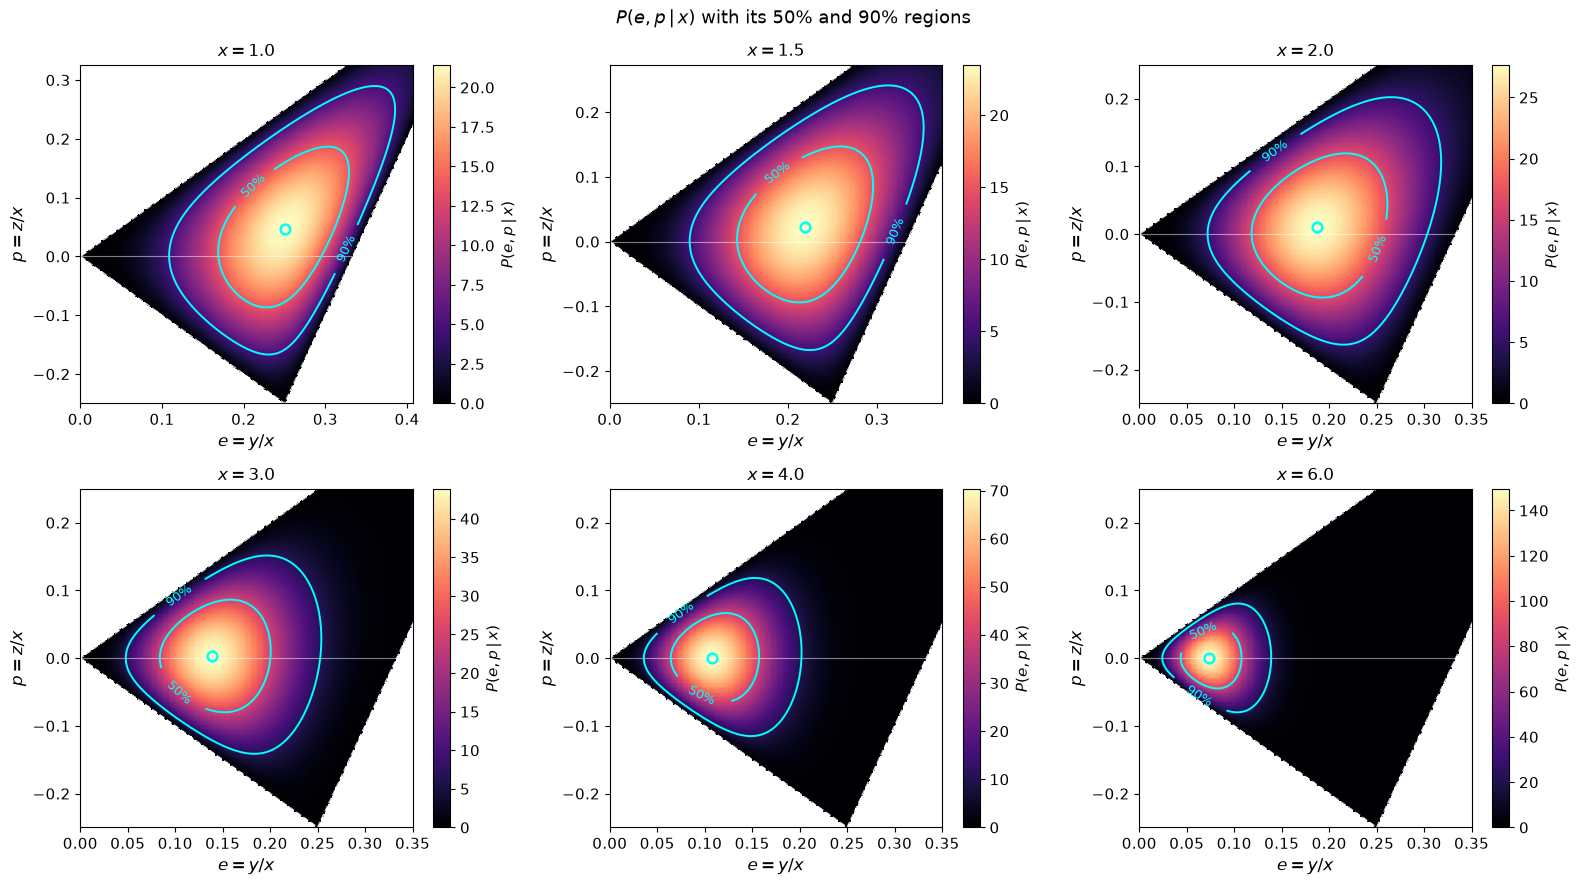

In [17]:
# --- the same distribution at several x: shapes become more spherical as x grows ---

x_values = [1.0, 1.5, 2.0, 3.0, 4.0, 6.0]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for x, ax in zip(x_values, axes.ravel()):
    plot_ep_heatmap(x, zoom=True, ngrid=400, ax=ax)
    ax.legend().set_visible(False)
    ax.set_title(rf"$x = {x}$", fontsize=12)

fig.suptitle(r"$P(e, p\,|\,x)$ with its 50% and 90% regions", fontsize=13)
fig.tight_layout()
plt.show()


Two features of the published figure come straight out of these panels. Peaks are **never spherical**: $e = 0$ is a vertex of the triangle where $W$ vanishes, so the density goes to zero there and the mode sits at finite ellipticity for every $x$. And the most probable $p$ collapses towards zero much faster than $e$ does ($p_m \propto e_m^4$), so even sharply curved peaks are **triaxial rather than oblate or prolate** — $\lambda_2 \approx (\lambda_1+\lambda_3)/2$, exactly as BBKS state below eq. (7.6).

A note on eq. (7.7). Its $e_m$ is excellent — within 1% of the true mode for $x \gtrsim 3$, and still within 2% at $x = 2.5$. Its $p_m$, printed as $6/(5x^4[1+6/(5x^2)]^2) = 30\,e_m^4$, is five times too large. Maximising $\ln V$ from Appendix C with respect to $p$ gives

$$p\left(5x^2 + \frac{2}{e^2} + 6\right) = 18e^2 \;\Longrightarrow\; p_m = \frac{18e_m^4}{2 + (5x^2+6)e_m^2} = 6\,e_m^4 ,$$

using $e_m^2 = 1/(5x^2+6)$. The table above shows $6e_m^4$ tracking the numerical mode to a few percent at large $x$, and it also recovers BBKS's own quoted $p_m \approx 5\times10^{-3}$ at $x \approx 2.5$, which the printed formula does not (it gives $0.022$). `ep_most_probable` therefore returns the corrected value.

The dispersions $\sigma_e = e_m/\sqrt6$ and $\sigma_p = e_m/\sqrt3$ are unaffected, and give the axial ratio $\sigma_p/\sigma_e = \sqrt2 \approx 1.4$ that BBKS quote for the contour ellipses of Fig. 7.

## 4. Finite-radius density profiles — BBKS §VII

Everything below uses the **same** filtered field defined in §1. No new \(P(k)\), \(W(kR_f)\), or
\(R_f\) is introduced.


### The normalized correlation function $\psi$

For a pure power law with a Gaussian filter there is a closed form,
$$\psi(r)={}_1F_1\!\left(\frac{n+3}{2};\frac32;-\frac{r^2}{4R_f^2}\right),$$
used below only as a check of the quadrature (it is *not* used anywhere else).

max |psi_numeric - psi_analytic| = 3.310685059432217e-13
lap psi(0) = -1.80000000   (must equal -3 gamma^2 = -1.80000000)
S(0)       = -0.00e+00     (must vanish)


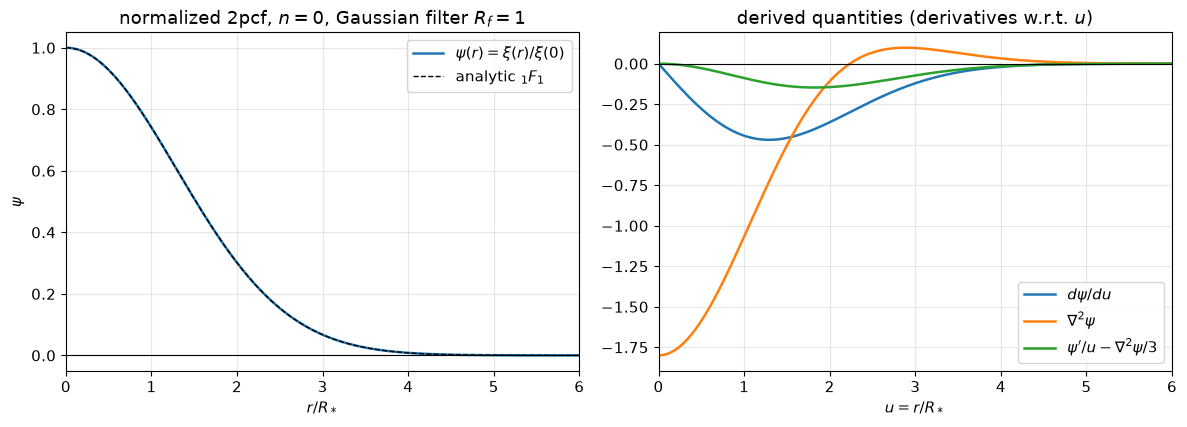

In [18]:
u_grid = np.linspace(0.0, 6.0, 1201)          # u = r/R_*
psi, dpsi, lap, S = field.profile_functions(u_grid)

psi_analytic = hyp1f1((n_index + 3) / 2, 1.5, -(u_grid * field.Rstar)**2 / (4 * R_f**2))
print("max |psi_numeric - psi_analytic| =", np.max(np.abs(psi - psi_analytic)))
print(f"lap psi(0) = {lap[0]:.8f}   (must equal -3 gamma^2 = {-3*field.gamma**2:.8f})")
print(f"S(0)       = {S[0]:.2e}     (must vanish)")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
ax[0].plot(u_grid, psi, label=r"$\psi(r)=\xi(r)/\xi(0)$")
ax[0].plot(u_grid, psi_analytic, "k--", lw=1, label=r"analytic $_1F_1$")
ax[0].axhline(0, color="k", lw=0.8)
ax[0].set_xlabel(r"$r/R_*$"); ax[0].set_ylabel(r"$\psi$")
ax[0].set_title(rf"normalized 2pcf, $n={n_index:g}$, Gaussian filter $R_f={R_f:g}$")
ax[0].legend(); ax[0].set_xlim(0, 6)

ax[1].plot(u_grid, dpsi, label=r"$d\psi/du$")
ax[1].plot(u_grid, lap, label=r"$\nabla^2\psi$")
ax[1].plot(u_grid, S, label=r"$\psi'/u-\nabla^2\psi/3$")
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_xlabel(r"$u=r/R_*$"); ax[1].set_title("derived quantities (derivatives w.r.t. $u$)")
ax[1].legend(); ax[1].set_xlim(0, 6)
plt.tight_layout(); plt.show()

### Mean shape (7.8), dispersion (7.9), and angular factor $A(e,p)$

$$\frac{\bar F(\mathbf r)}{\sigma_0}=\frac{\nu}{1-\gamma^2}\left(\psi+\frac{\nabla^2\psi}{3}\right)
-\frac{x/\gamma}{1-\gamma^2}\left(\gamma^2\psi+\frac{\nabla^2\psi}{3}\right)
+\frac52\frac{x}{\gamma}\left(\frac{\psi'}{r}-\frac{\nabla^2\psi}{3}\right)A(e,p)$$

$$\frac{\langle[\Delta F]^2|C\rangle}{\sigma_0^2}=1-\frac{\psi^2}{1-\gamma^2}
-\frac{1}{\gamma^2(1-\gamma^2)}\left(2\gamma^2\psi+\frac{\nabla^2\psi}{3}\right)\frac{\nabla^2\psi}{3}
-\frac{5}{\gamma^2}\left(\frac{\psi'}{r}-\frac{\nabla^2\psi}{3}\right)^2-\frac{1}{\gamma^2}(\psi')^2$$

with (eq. 7.4), the 1-axis being the polar axis and $x_3=r\sin\theta\sin\phi$,
$$A(e,p)=3e\left[1-\sin^2\theta(1+\sin^2\phi)\right]+p\left(1-3\sin^2\theta\cos^2\phi\right).$$

Along the three principal axes this reduces to three numbers,
$$A_1=3e+p,\qquad A_2=-2p,\qquad A_3=p-3e ,$$
which is exactly the statement $\lambda_i=\tfrac13(\sum_j\lambda_j)(1+A_i)$ with the $\lambda_i$
recovered from $e,p$ — since $\lambda_1\ge\lambda_2\ge\lambda_3$, the profile falls off fastest along
the 1-axis and slowest along the 3-axis.

The allowed domain of $(e,p)$ is the triangle of eq. (C3): $0\le e\le\frac14$ with $-e\le p\le e$, and
$\frac14\le e\le\frac12$ with $-(1-3e)\le p\le e$.

In [19]:
def A_angular(e, p, theta, phi):
    '''BBKS eq. (7.4); 1-axis is the polar axis, x3 = r sin(theta) sin(phi).'''
    st2 = np.sin(theta)**2
    return 3 * e * (1 - st2 * (1 + np.sin(phi)**2)) + p * (1 - 3 * st2 * np.cos(phi)**2)


def A_principal(e, p):
    '''A(e,p) along the 1-, 2- and 3-axis.'''
    return 3 * e + p, -2 * p, p - 3 * e


def mean_profile(fld, u, nu, x, A, funcs=None):
    '''BBKS eq. (7.8)  ->  Fbar(r)/sigma_0.  A = A(e,p) for the chosen direction
    (A = 0 gives the orientation-averaged eq. 7.10).'''
    psi, dpsi, lap, S = fld.profile_functions(u) if funcs is None else funcs
    g = fld.gamma
    return (nu / (1 - g**2) * (psi + lap / 3)
            - (x / g) / (1 - g**2) * (g**2 * psi + lap / 3)
            + 2.5 * (x / g) * S * A)

def mean_profile_new(u, nu, x, A, gamma, funcs):
    '''BBKS eq. (7.8)  ->  Fbar(r)/sigma_0.  A = A(e,p) for the chosen direction
    (A = 0 gives the orientation-averaged eq. 7.10).'''
    psi, dpsi, lap, S = funcs
    g = gamma
    return (nu / (1 - g**2) * (psi + lap / 3)
            - (x / g) / (1 - g**2) * (g**2 * psi + lap / 3)
            + 2.5 * (x / g) * S * A)


def profile_dispersion(fld, u, funcs=None):
    '''BBKS eq. (7.9)  ->  sqrt(<dF^2|C>)/sigma_0.  Independent of nu, x, e, p.'''
    psi, dpsi, lap, S = fld.profile_functions(u) if funcs is None else funcs
    g = fld.gamma
    var = (1 - psi**2 / (1 - g**2)
           - (1 / (g**2 * (1 - g**2))) * (2 * g**2 * psi + lap / 3) * (lap / 3)
           - (5 / g**2) * S**2
           - (1 / g**2) * dpsi**2)
    return np.sqrt(np.clip(var, 0, None))

def profile_dispersion_new(u, gamma, funcs):
    '''BBKS eq. (7.9)  ->  sqrt(<dF^2|C>)/sigma_0.  Independent of nu, x, e, p.'''
    psi, dpsi, lap, S = funcs
    g = gamma
    var = (1 - psi**2 / (1 - g**2)
           - (1 / (g**2 * (1 - g**2))) * (2 * g**2 * psi + lap / 3) * (lap / 3)
           - (5 / g**2) * S**2
           - (1 / g**2) * dpsi**2)
    return np.sqrt(np.clip(var, 0, None))


def ep_allowed(e, p):
    '''characteristic function chi(e,p), BBKS eq. (C3).'''
    if 0 <= e <= 0.25:
        return -e <= p <= e
    if 0.25 < e <= 0.5:
        return -(1 - 3 * e) <= p <= e
    return False


def most_probable_ep(x):
    '''Mode of the exact P(e,p|x), eq. (7.6) with W(e,p) of eq. (C4):
       P ~ e(e^2-p^2)(1-2p)[(1+p)^2-9e^2] exp[-(5/2)x^2(3e^2+p^2)].'''
    def neg_lnP(v):
        e, p = v
        if not ep_allowed(e, p) or e <= 0:
            return 1e9
        Wpoly = e * (e**2 - p**2) * (1 - 2 * p) * ((1 + p)**2 - 9 * e**2)
        if Wpoly <= 0:
            return 1e9
        return -(np.log(Wpoly) - 2.5 * x**2 * (3 * e**2 + p**2))
    r = minimize(neg_lnP, [min(0.2, 0.9 / (np.sqrt(5) * max(x, 0.5))), 5e-3],
                 method="Nelder-Mead", options=dict(xatol=1e-9, fatol=1e-12, maxiter=20000))
    return float(r.x[0]), float(r.x[1])

### Sanity checks

In [20]:
nu_t, x_t, e_t, p_t = 2.68, 2.5, 0.17, 0.005   # x_t is just a test value here
u_t = np.array([0.0, 1e-3, 1e-2, 3e-2, 0.1])
f_t = field.profile_functions(u_t)

print("Fbar(0)/sigma0 =", mean_profile(field, u_t, nu_t, x_t, 0.0, f_t)[0], " (must be nu =", nu_t, ")")
print("dispersion(0)  =", profile_dispersion(field, u_t, f_t)[0], " (must vanish)")
print("dispersion(inf)=", profile_dispersion(field, np.array([30.0]))[0], " (must -> 1)")

print("\nsmall-r limit, eq. (7.8) vs eq. (7.4) with the corrected r^2/6 coefficient:")
for A, lab in zip(A_principal(e_t, p_t), ["1-axis", "2-axis", "3-axis"]):
    exact = mean_profile(field, u_t, nu_t, x_t, A, f_t)
    taylor = nu_t - x_t * field.sigma2 * (u_t * field.Rstar)**2 / (6 * field.sigma0) * (1 + A)
    print(f"  {lab}: max|diff| = {np.max(np.abs(exact - taylor)):.2e}")

em, pm = most_probable_ep(x_t)
print(f"\nmost probable (e,p) at x={x_t}: e_m = {em:.4f}, p_m = {pm:.5f}"
      f"   [BBKS quote ~0.17 and ~5e-3]")

Fbar(0)/sigma0 = 2.6799999999990973  (must be nu = 2.68 )
dispersion(0)  = 8.137180174276856e-07  (must vanish)
dispersion(inf)= 1.0  (must -> 1)

small-r limit, eq. (7.8) vs eq. (7.4) with the corrected r^2/6 coefficient:
  1-axis: max|diff| = 3.19e-05
  2-axis: max|diff| = 1.67e-05
  3-axis: max|diff| = 2.32e-06

most probable (e,p) at x=2.5: e_m = 0.1603, p_m = 0.00513   [BBKS quote ~0.17 and ~5e-3]


## Interactive: the average shape along the three principal axes

Sliders set $\nu$, $x$ and the asymmetry parameters $e,p$; the curves are eq. (7.8) evaluated with
$A_1=3e+p$, $A_2=-2p$, $A_3=p-3e$, plus the spherical ($A=0$) case for reference. This is the
BBKS Fig. 9 construction.

Note that $x$ here is the peak curvature in the *text* convention, $x=-\nabla^2F/\sigma_2$
(BBKS warn that the $x$ of Figs. 6–7 is $1.58\approx\gamma^{-1}$ times this one). A natural default
is $x_*=\gamma\nu$; the most probable $x$ for high peaks is somewhat larger ($\sim1.5\,x_*$ in the
CDM example of § VII*a*). The $\pm1\sigma$ band from eq. (7.9) is independent of $\nu,x,e,p$.

In [21]:
u_plot = np.linspace(0.0, 6.0, 601)
funcs_plot = field.profile_functions(u_plot)          # computed once
sig_plot = profile_dispersion(field, u_plot, funcs_plot)
print(sig_plot[0], sig_plot[-1])   # check: 0 at u=0, ->1 at u->inf

def plot_shapes(e=0.17, p=0.005, nu=2.68, x=2.5, show_band=True, show_sphere=True, show_dist=True):
    ok = ep_allowed(e, p)
    fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(6, 5.0))
    colors = ["#c112b5", "#6b41cd", "#2a9d8f"]
    for A, lab, c in zip(A_principal(e, p), ["1-axis (steepest)", "2-axis", "3-axis (shallowest)"], colors):
        prf = mean_profile(field, u_plot, nu, x, A, funcs_plot)
        ax.plot(u_plot, prf, color=c, label=lab)
        if show_band:
            ax.fill_between(u_plot, prf - sig_plot, prf + sig_plot, color=c, alpha=0.18,label=r"$\pm1\sigma$")
    if show_sphere:
        m0 = mean_profile(field, u_plot, nu, x, 0.0, funcs_plot)
        ax.plot(u_plot, m0, "k--", lw=1.4, label=r"spherical mean")

    ax.set_xlabel(r"$r/R_*$", fontsize=13); ax.set_ylabel(r"$\bar F(r)/\sigma_0$", fontsize=13)
    ax.set_title(rf"Profiles: $\nu={nu:.2f}$, $x={x:.2f}$, $e={e:.3f}$, $p={p:.3f}$, "
                 rf"$\gamma={field.gamma:.3f}$" + ("" if ok else "   [(e,p) OUTSIDE allowed domain!]"),
                 color="k" if ok else "crimson", fontsize=13)
    ax.axhline(0, color="k", lw=0.8); ax.legend(loc="upper right"); ax.set_xlim(0, u_plot[-1])
    if show_dist:
        ax1 = ax.inset_axes([0.8, 0.75, 0.2, 0.25])
        ax2 = ax.inset_axes([0.8, 0.45, 0.2, 0.25])
        x_nu_plot_point(nu, x, x_mean, x_std, ax = ax2)
        plot_ep_heatmap_point(x, e, p, kind=KIND, zoom=ZOOM, ngrid=NGRID, ax = ax1)
    ax.grid(False)
    plt.tight_layout(); plt.show()

# plot_shapes()   # static example, in case ipywidgets is not available


8.137180174276856e-07 0.9999999467590803


### Interactive plot
Since the peak profile is conditioned to $x,e,p$ and $\nu$ but we also computed the probability densities $P(e,p|x)$ and $P(x|\nu)$ once we choose the peak parameters we can also look at how they are positioned with respect to such distributions

In [22]:
%matplotlib inline
import ipywidgets as w
from IPython.display import display

ctrl = dict(
    e  = w.FloatSlider(value=0.076,  min=0.0, max=0.5, step=0.005,
                       description="e",  continuous_update=False, readout_format=".3f"),
    p  = w.FloatSlider(value=0.000, min=-0.5, max=0.5, step=0.005,
                       description="p",  continuous_update=False, readout_format=".3f"),
    nu = w.FloatSlider(value=5,  min=0.5, max=8.0, step=0.01,
                       description="ν",  continuous_update=False, readout_format=".2f"),
    x  = w.FloatSlider(value=5.9,   min=0.0, max=8.0, step=0.01,
                       description="x",  continuous_update=False, readout_format=".2f"),
    show_band   = w.Checkbox(value=True, description="±1σ band"),
    show_sphere = w.Checkbox(value=True, description="spherical mean"),
    show_dist = w.Checkbox(value=False, description="show e,p,x distributions"),
)

# keep p inside [-e, e] as e moves (order matters or ipywidgets complains)
def _sync_p(change):
    e = change["new"]
    if -e > ctrl["p"].max:
        ctrl["p"].max, ctrl["p"].min = e, -e
    else:
        ctrl["p"].min, ctrl["p"].max = -e, e
ctrl["e"].observe(_sync_p, names="value")

ui = w.VBox([w.HBox([ctrl["e"], ctrl["p"]]),
             w.HBox([ctrl["nu"], ctrl["x"]]),
             w.HBox([ctrl["show_band"], ctrl["show_sphere"], ctrl["show_dist"]])])
display(ui, w.interactive_output(plot_shapes, ctrl))

Output()

## 5. Spherical averaged distribution
Since in the code simulations we only categorize the peaks by their height $\nu$ idependently of their curvature, to get the distribution of a peak given only its height we need to marginalize over the $x,e,p$ and Euler angles (the latter is equivalent to perform a spherical average on $\theta$ and $\phi$). Since the final distribution isn't gaussian anymore we perform the marginalization by numerical Monte Carlo integration.

In [23]:
def sample_x_e_p_given_nu(nu, gamma=gamma, n_samples=20000, n_x=161, n_e=161, n_p=161, x_max=None, rng=None):
    '''Draw samples (x, e, p) from the joint conditional distribution P(x,e,p|nu), BBKS.

    The FULL unconditional (curvature, shape) density is (BBKS eq. C4, with the correct
    x^8 prefactor -- this is the piece that was missing/wrong before):

        N(x,e,p) propto x^8 * Wpoly(e,p) * exp(-5x^2 Q(e,p)/2),
        Wpoly(e,p) = e(e^2-p^2)(1-2p)[(1+p)^2-9e^2],   Q(e,p) = 3e^2+p^2,

    on the domain 0<=e<=1/2 (eq. C3). Conditioning on nu multiplies this by the
    (x-nu) correlation Gaussian, exp[-(x-x*)^2/(2(1-gamma^2))] with x*=gamma*nu:

        P(x,e,p|nu) propto exp[-(x-x*)^2/(2(1-gamma^2))] * x^8 * Wpoly * exp(-5x^2Q/2).

    Marginalising this over (e,p) reproduces f_bbks(x) up to a constant, and marginalising
    over x reproduces average_ep_given_nu -- both checked numerically to confirm this is
    the correct joint (earlier versions either double-counted f(x) or dropped x^8 entirely).
    '''
    rng = np.random.default_rng() if rng is None else rng
    if x_max is None:
        x_max = gamma * nu + 6.0 / np.sqrt(1 - gamma**2)

    x_grid = np.linspace(1e-4, x_max, n_x)
    e_grid = np.linspace(1e-4, 0.5, n_e)
    p_grid = np.linspace(-0.5, 0.5, n_p)
    X, E, P = np.meshgrid(x_grid, e_grid, p_grid, indexing='ij')

    lower = np.where(E <= 0.25, -E, -(1 - 3 * E))
    domain = (P >= lower) & (P <= E)
    Wpoly = E * (E**2 - P**2) * (1 - 2 * P) * ((1 + P)**2 - 9 * E**2)
    Wpoly = np.where(domain & (Wpoly > 0), Wpoly, 0.0)

    x_star = gamma * nu
    joint = (np.exp(-(X - x_star)**2 / (2 * (1 - gamma**2)))
             * X**8 * Wpoly * np.exp(-2.5 * X**2 * (3 * E**2 + P**2)))

    probs = joint.ravel()
    probs = probs / probs.sum()

    idx = rng.choice(probs.size, size=n_samples, p=probs)
    ix, ie, ip = np.unravel_index(idx, joint.shape)

    dx, de, dp = x_grid[1] - x_grid[0], e_grid[1] - e_grid[0], p_grid[1] - p_grid[0]
    x_s = np.clip(x_grid[ix] + rng.uniform(-dx / 2, dx / 2, n_samples), 1e-6, None)
    e_s = np.clip(e_grid[ie] + rng.uniform(-de / 2, de / 2, n_samples), 1e-6, 0.5)
    p_s = np.clip(p_grid[ip] + rng.uniform(-dp / 2, dp / 2, n_samples), -0.5, 0.5)
    return x_s, e_s, p_s


def profile_distribution_at_r_full(u, nu, gamma=gamma, n_samples=20000,
                                    n_x=81, n_e=81, n_p=81,
                                    F_grid=None, n_F=400, rng=None, sigma=None):
    '''
    The accurate spherically-averaged distribution of the profile value F at r/R_star = u,
    for peaks of height nu: convolves the fixed-sigma Gaussian (BBKS eq. 7.9) with the
    FULL JOINT distribution of curvature x and shape (e, p) given nu, and with the uniform
    distribution of orientation (theta, phi) -- rather than fixing x, e, p at their means.

    Returns
    -------
    F_grid   : ndarray            grid of profile values where P(F|u,nu) is evaluated
    P_F      : ndarray            normalised density P(F|u,nu) on F_grid
    F_mean   : float              mean of the computed distribution, int F P(F|u,nu) dF
    sigma    : float              the (direction-independent) BBKS dispersion at this u
    means    : ndarray            the per-sample means (x_i, e_i, p_i, theta_i, phi_i) used
    '''

    rng = np.random.default_rng() if rng is None else rng
    funcs = field.profile_functions(u)
    if sigma is None:
        sigma = profile_dispersion_new(u, gamma, funcs).item()
    x_s, e_s, p_s = sample_x_e_p_given_nu(nu, gamma, n_samples, n_x, n_e, n_p, rng=rng)

    cos_theta = rng.uniform(-1.0, 1.0, n_samples)         # uniform on the sphere
    theta_s = np.arccos(cos_theta)
    phi_s = rng.uniform(0.0, 2 * np.pi, n_samples)

    A_s = A_angular(e_s, p_s, theta_s, phi_s)
    means = mean_profile_new(u, nu, x_s, A_s, gamma, funcs)     # (n_samples,)

    if sigma > 0:
        if F_grid is None:
            F_lo = means.min() - 5 * sigma
            F_hi = means.max() + 5 * sigma
            F_grid = np.linspace(F_lo, F_hi, n_F)

        diff = (F_grid[:, None] - means[None, :]) / sigma
        P_F = (np.exp(-0.5 * diff**2) / (sigma * np.sqrt(2 * np.pi))).mean(axis=1)
        P_F /= simpson(P_F, x=F_grid)

        F_mean = simpson(F_grid * P_F, x=F_grid)
        F_var = simpson((F_grid - F_mean)**2 * P_F, x=F_grid)
        F_std = np.sqrt(F_var)
        return F_grid, P_F, F_mean, F_std, sigma, means
    else:
        # sigma=0 case: the distribution is a delta function at the mean
        F_mean = means.mean()
        return np.array([F_mean]), np.array([1.0]), F_mean, 0.0, sigma, means

In [24]:
# Calculate theoretical prediction
u_profile = np.linspace(0., 6.0, 101)
nu = 3
gamma = field.gamma

p_avg = np.zeros_like(u_profile)
p_std = np.zeros_like(u_profile)
for u in u_profile:
    F_grid, P_F, F_mean, F_std, sigma, means = profile_distribution_at_r_full(u, nu, gamma, n_samples=100000, n_x=128, n_e=128, n_p=128)
    p_avg[np.isclose(u_profile, u)] = F_mean
    p_std[np.isclose(u_profile, u)] = F_std

In [25]:
funcs_plot_wrong = field.profile_functions(u_profile)          # computed once
sig_plot_wrong = profile_dispersion(field, u_profile, funcs_plot_wrong)

### Plot
Now we can plot the averaged profile and the 1-sigma band from the marginalized distribution

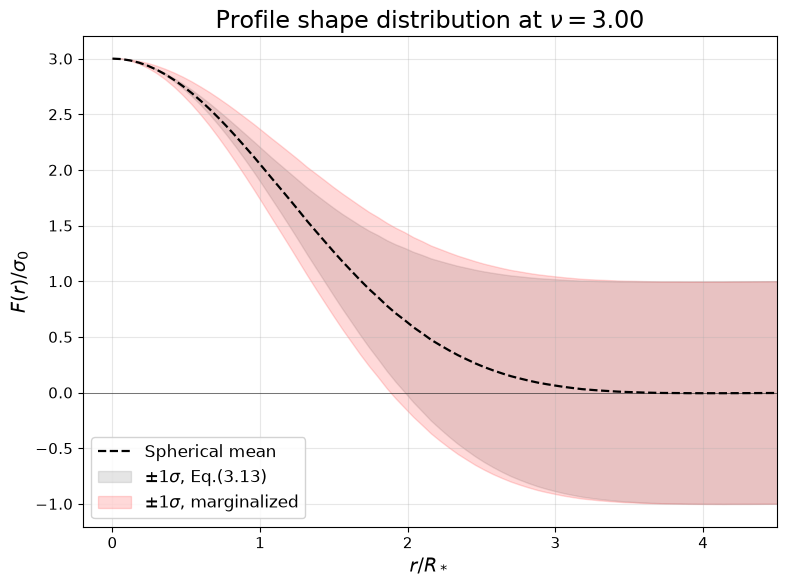

In [28]:
band_nsigma = 1.0  # Number of standard deviations for the band

fig, ax = plt.subplots(figsize=(8, 6))
# Plot theoretical prediction
ax.set_title(rf"Profile shape distribution at $\nu={nu:.2f}$", fontsize=17)
ax.plot(u_profile, p_avg, "k--", lw=1.6,label=r"Spherical mean")
ax.fill_between(u_profile,p_avg - band_nsigma * sig_plot_wrong,p_avg + band_nsigma * sig_plot_wrong,color="gray",alpha=0.2,label=fr"$\pm{band_nsigma:g}\sigma$, Eq.(3.13)")
ax.fill_between(u_profile,p_avg - band_nsigma * p_std,p_avg + band_nsigma * p_std,color="red",alpha=0.15,label=fr"$\pm{band_nsigma:g}\sigma$, marginalized")

ax.axhline(0, color="k", lw=0.7, alpha=0.5)

ax.set_xlabel(r"$r/R_*$", fontsize=14)
ax.set_ylabel(r"$F(r)/\sigma_0$", fontsize=14)

ax.set_xlim(-0.2,4.5)
#ax.set_ylim(2.76,2.77)


ax.legend(loc="lower left", fontsize=12, framealpha=0.85)
plt.tight_layout()

plt.show()


At r/R* = 0.8: mean = 2.35311, std = 0.21376, sigma = 0.08424
At r/R* = 1.5: mean = 1.26221, std = 0.57970, sigma = 0.39313
At r/R* = 2.2: mean = 0.44017, std = 0.85620, sigma = 0.74496
At r/R* = 3: mean = 0.06176, std = 0.97747, sigma = 0.95144


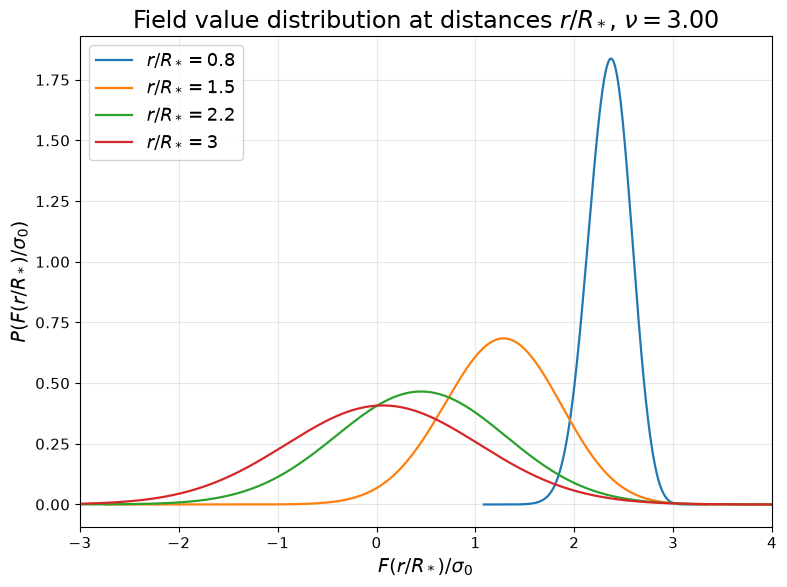

In [27]:
radi = [0.8,1.5,2.2,3]

plt.figure(figsize=(8,6))

for r in radi:
    F_grid, P_F, F_mean, F_std, sigma, means = profile_distribution_at_r_full(r, nu, gamma, n_samples=100000, n_x=128, n_e=128, n_p=128)
    plt.plot(F_grid, P_F, lw=1.6,label=rf"$r/R_*={r}$")
    print(f"At r/R* = {r}: mean = {F_mean:.5f}, std = {F_std:.5f}, sigma = {sigma:.5f}")
plt.xlim(-3, 4)
plt.xlabel(r"$F(r/R_*)/\sigma_0$", fontsize=14)
plt.ylabel(r"$P(F(r/R_*)/\sigma_0)$", fontsize=14)
plt.legend(fontsize=13, framealpha=0.85)
plt.title(rf"Field value distribution at distances $r/R_*$, $\nu={nu:.2f}$", fontsize=17)
plt.tight_layout()
plt.show()